In [1]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_csv("../data/raw/Data_for_UCI_named.csv")
print(df.shape)
df.head()

(10000, 14)


,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab,stabf
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347,unstable
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957,stable
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471,unstable
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871,unstable
4,3.134112,7.608772,4.943759,9.857573,3.525811,-1.125531,-1.845975,-0.554305,0.797110,0.455450,0.656947,0.820923,0.049860,unstable


In [3]:
df.info()
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tau1    10000 non-null  float64
 1   tau2    10000 non-null  float64
 2   tau3    10000 non-null  float64
 3   tau4    10000 non-null  float64
 4   p1      10000 non-null  float64
 5   p2      10000 non-null  float64
 6   p3      10000 non-null  float64
 7   p4      10000 non-null  float64
 8   g1      10000 non-null  float64
 9   g2      10000 non-null  float64
 10  g3      10000 non-null  float64
 11  g4      10000 non-null  float64
 12  stab    10000 non-null  float64
 13  stabf   10000 non-null  str    
dtypes: float64(13), str(1)
memory usage: 1.1 MB
tau1     0
tau2     0
tau3     0
tau4     0
p1       0
p2       0
p3       0
p4       0
g1       0
g2       0
g3       0
g4       0
stab     0
stabf    0
dtype: int64


In [4]:
print("Duplicate rows:", df.duplicated().sum())
print(df["stabf"].value_counts())
print(df["stabf"].value_counts(normalize=True))

Duplicate rows: 0
stabf
unstable    6380
stable      3620
Name: count, dtype: int64
stabf
unstable    0.638
stable      0.362
Name: proportion, dtype: float64


In [5]:
check = (df["p1"] - (df["p2"] + df["p3"] + df["p4"]).abs()).abs()
print("Max difference:", check.max())

Max difference: 6.217248937900877e-15


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
tau1,10000.0,5.250000,2.742548,0.500793,2.874892,5.250004,7.624690,9.999469
tau2,10000.0,5.250001,2.742549,0.500141,2.875140,5.249981,7.624893,9.999837
tau3,10000.0,5.250004,2.742549,0.500788,2.875522,5.249979,7.624948,9.999450
tau4,10000.0,5.249997,2.742556,0.500473,2.874950,5.249734,7.624838,9.999443
p1,10000.0,3.750000,0.752160,1.582590,3.218300,3.751025,4.282420,5.864418
p2,10000.0,-1.250000,0.433035,-1.999891,-1.624901,-1.249966,-0.874977,-0.500108
p3,10000.0,-1.250000,0.433035,-1.999945,-1.625025,-1.249974,-0.875043,-0.500072
p4,10000.0,-1.250000,0.433035,-1.999926,-1.624960,-1.250007,-0.875065,-0.500025
g1,10000.0,0.525000,0.274256,0.050009,0.287521,0.525009,0.762435,0.999937
g2,10000.0,0.525000,0.274255,0.050053,0.287552,0.525003,0.762490,0.999944


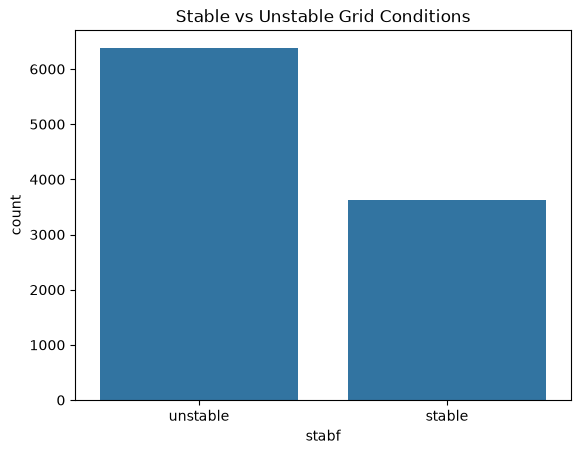

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="stabf")
plt.title("Stable vs Unstable Grid Conditions")
plt.savefig("../reports/figures/class_counts.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
tau1,10000.0,5.250000,2.742548,0.500793,2.874892,5.250004,7.624690,9.999469
tau2,10000.0,5.250001,2.742549,0.500141,2.875140,5.249981,7.624893,9.999837
tau3,10000.0,5.250004,2.742549,0.500788,2.875522,5.249979,7.624948,9.999450
tau4,10000.0,5.249997,2.742556,0.500473,2.874950,5.249734,7.624838,9.999443
p1,10000.0,3.750000,0.752160,1.582590,3.218300,3.751025,4.282420,5.864418
p2,10000.0,-1.250000,0.433035,-1.999891,-1.624901,-1.249966,-0.874977,-0.500108
p3,10000.0,-1.250000,0.433035,-1.999945,-1.625025,-1.249974,-0.875043,-0.500072
p4,10000.0,-1.250000,0.433035,-1.999926,-1.624960,-1.250007,-0.875065,-0.500025
g1,10000.0,0.525000,0.274256,0.050009,0.287521,0.525009,0.762435,0.999937
g2,10000.0,0.525000,0.274255,0.050053,0.287552,0.525003,0.762490,0.999944


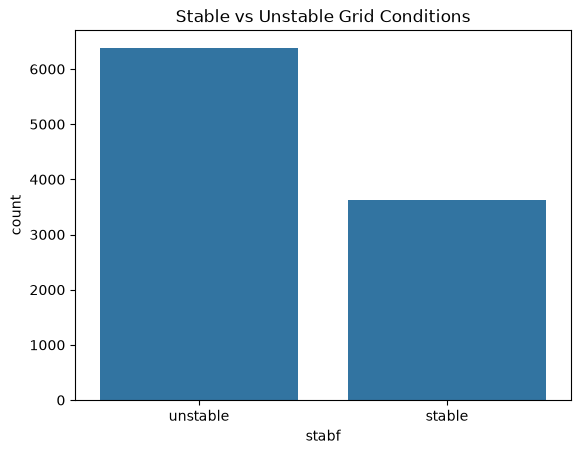

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="stabf")
plt.title("Stable vs Unstable Grid Conditions")
plt.savefig("../reports/figures/class_counts.png", dpi=150, bbox_inches="tight")
plt.show()

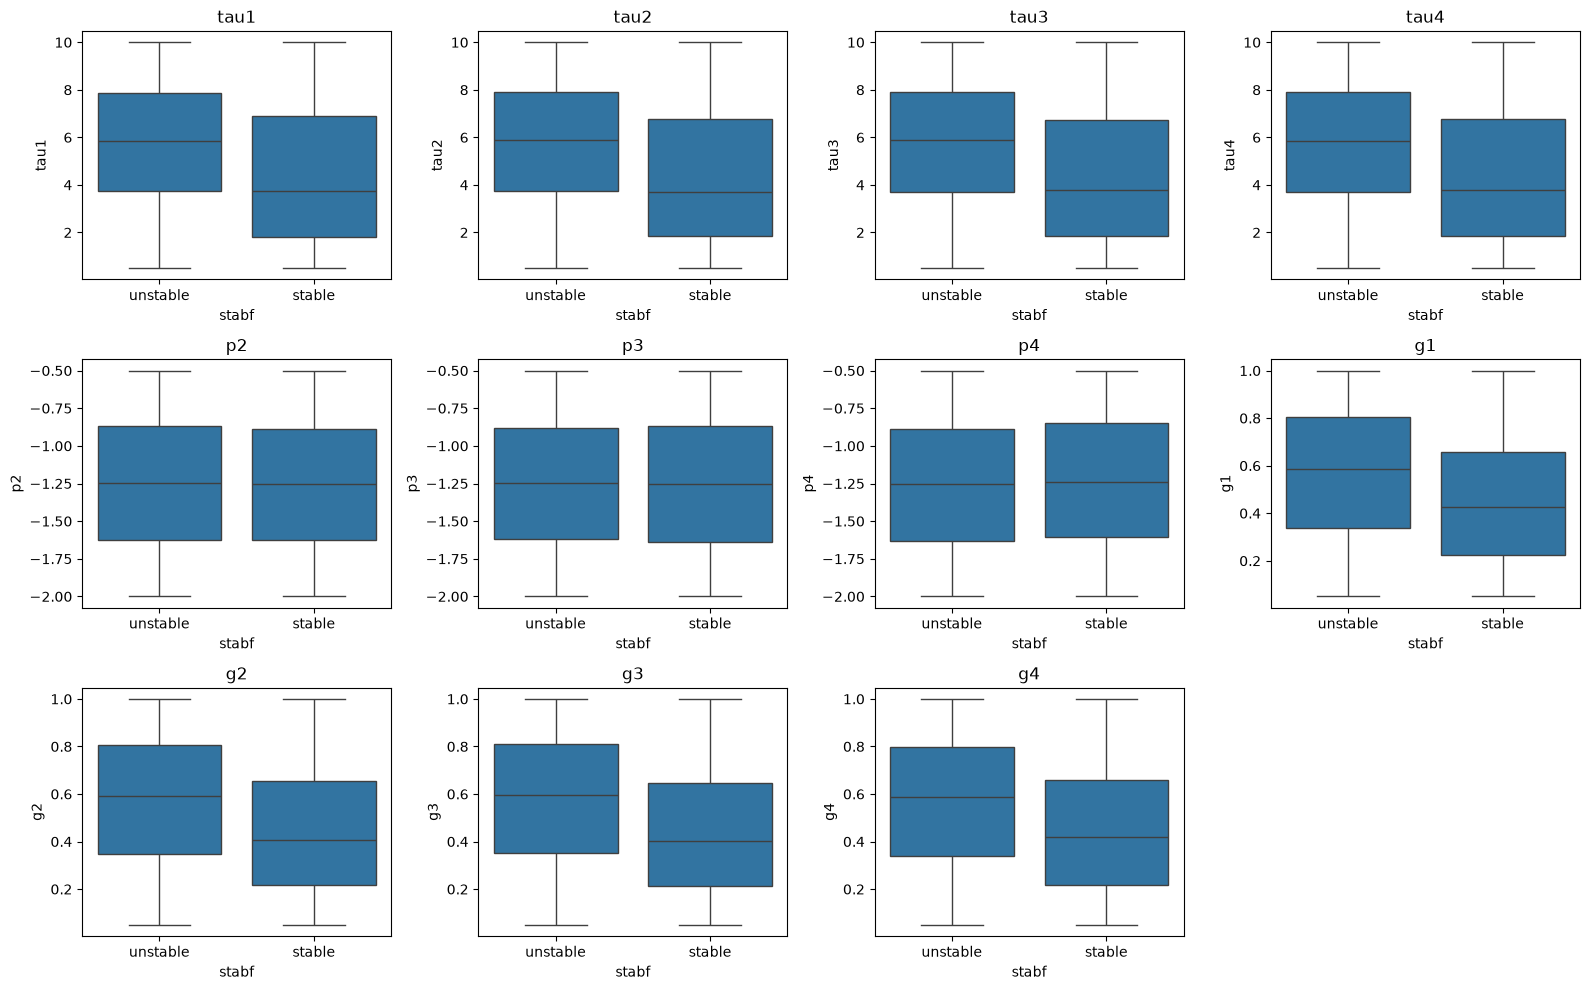

In [10]:
features = ["tau1", "tau2", "tau3", "tau4", "p2", "p3", "p4", "g1", "g2", "g3", "g4"]

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, features):
    sns.boxplot(data=df, x="stabf", y=col, ax=ax)
    ax.set_title(col)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.savefig("../reports/figures/boxplots_by_stability.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
df.groupby("stabf")[features].mean().T

stabf,stable,unstable
tau1,4.394799,5.735239
tau2,4.353362,5.758752
tau3,4.385360,5.740601
tau4,4.378495,5.744485
p2,-1.253549,-1.247987
p3,-1.249626,-1.250212
p4,-1.236902,-1.257431
g1,0.453035,0.565832
g2,0.445872,0.569897
g3,0.440618,0.572879


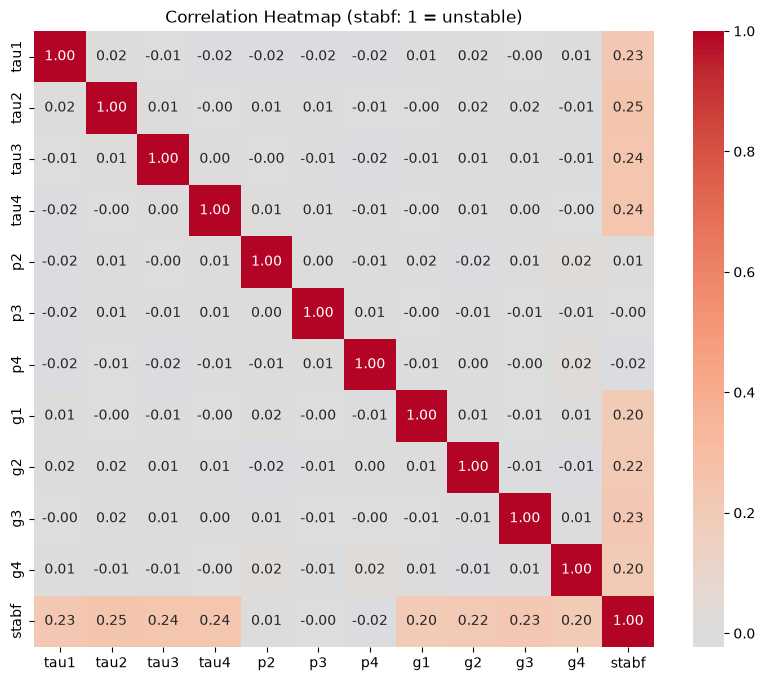

In [13]:
corr = df[features + ["stabf"]].assign(stabf=(df["stabf"] == "unstable").astype(int)).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (stabf: 1 = unstable)")
plt.savefig("../reports/figures/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

df = pd.read_csv("../data/raw/Data_for_UCI_named.csv")

features = ["tau1", "tau2", "tau3", "tau4", "p2", "p3", "p4", "g1", "g2", "g3", "g4"]
X = df[features]
y = (df["stabf"] == "unstable").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(8000, 11) (2000, 11)
0.638 0.638


In [15]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix)

log_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)),
])

log_reg.fit(X_train, y_train)
pred = log_reg.predict(X_test)

print("Test accuracy :", accuracy_score(y_test, pred))
print("Precision (unstable):", precision_score(y_test, pred))
print("Recall (unstable)   :", recall_score(y_test, pred))
print("F1 (unstable)       :", f1_score(y_test, pred))
print(confusion_matrix(y_test, pred))

Test accuracy : 0.82
Precision (unstable): 0.8407738095238095
Recall (unstable)   : 0.8855799373040752
F1 (unstable)       : 0.8625954198473282
[[ 510  214]
 [ 146 1130]]


In [16]:
coefs = pd.Series(log_reg.named_steps["model"].coef_[0], index=features)
print(coefs.sort_values())

p4     -0.043503
p2      0.007524
p3      0.042891
g1      0.742518
g4      0.779722
g2      0.783437
tau1    0.838661
g3      0.845398
tau4    0.864361
tau3    0.869124
tau2    0.881552
dtype: float64


In [17]:
from sklearn.tree import DecisionTreeClassifier

def report(name, model, X_te, y_te):
    p = model.predict(X_te)
    print(name)
    print("  accuracy :", round(accuracy_score(y_te, p), 4))
    print("  precision:", round(precision_score(y_te, p), 4))
    print("  recall   :", round(recall_score(y_te, p), 4))
    print("  f1       :", round(f1_score(y_te, p), 4))
    print(confusion_matrix(y_te, p))

tree = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=RANDOM_STATE)
tree.fit(X_train, y_train)

report("Decision Tree (max_depth=5), TEST", tree, X_test, y_test)
report("Decision Tree (max_depth=5), TRAIN", tree, X_train, y_train)

Decision Tree (max_depth=5), TEST
  accuracy : 0.792
  precision: 0.8219
  recall   : 0.8605
  f1       : 0.8407
[[ 486  238]
 [ 178 1098]]
Decision Tree (max_depth=5), TRAIN
  accuracy : 0.815
  precision: 0.8395
  recall   : 0.8779
  f1       : 0.8583
[[2039  857]
 [ 623 4481]]


In [18]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1
)
forest.fit(X_train, y_train)

report("Random Forest, TEST", forest, X_test, y_test)
report("Random Forest, TRAIN", forest, X_train, y_train)

imp = pd.Series(forest.feature_importances_, index=features).sort_values(ascending=False)
print(imp)

Random Forest, TEST
  accuracy : 0.9285
  precision: 0.9282
  recall   : 0.9624
  f1       : 0.945
[[ 629   95]
 [  48 1228]]
Random Forest, TRAIN
  accuracy : 0.9909
  precision: 0.9897
  recall   : 0.9961
  f1       : 0.9929
[[2843   53]
 [  20 5084]]
tau2    0.135874
tau3    0.132200
tau1    0.131787
tau4    0.131207
g3      0.108863
g4      0.103136
g1      0.101641
g2      0.099914
p2      0.018806
p4      0.018586
p3      0.017986
dtype: float64
